In [1]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MEAN, STD = 0.1307, 0.3081
BATCH_SIZE = 128
print("Using device:", DEVICE)

Using device: cpu


In [ ]:
## Define how to transform and normalize the images
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,))
])

## Load MNIST dataset 
full_train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

## Split training data 
train_size = 54_000
val_size = len(full_train_dataset) - train_size
generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size], generator=generator
)

## Create dataloaders to load batches
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## Print the number of images in each dataset
print(f"Training: {len(train_dataset):,}; validation: {len(val_dataset):,}; test: {len(test_dataset):,}")

100.0%
100.0%
100.0%
100.0%

Training: 54,000; validation: 6,000; test: 10,000


In [ ]:
class MNIST_CNN(nn.Module):
    def __init__(self, dropout_rate=0.25): ##Initialize the CNN 
        super().__init__() ##Initialze the parent nn.Module class
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1) ##First convolutional layer
        self.relu1 = nn.ReLU() ##Introduce nonlineraity into the network
        self.pool1 = nn.MaxPool2d(2) ##Reduce size of the feature maps 
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) ##Second convolutional layer
        self.relu2 = nn.ReLU() ##Introduce nonlineraity into the network
        self.pool2 = nn.MaxPool2d(2) ##Reduce size of the feature maps
        self.dropout = nn.Dropout(dropout_rate) ## Dropout rate is 0.25
        self.fc1 = nn.Linear(64 * 7 * 7, 128) ## First fully connected layer
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10) ##Final fully connecetd layer

    def forward(self, x): #Define the order that layers process images
        x = self.pool1(self.relu1(self.conv1(x))) ## 1st Convolution, ReLu activation, Max pooling
        x = self.pool2(self.relu2(self.conv2(x))) ## 2nd convolution, RELu activation, Max pooling
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(self.relu3(self.fc1(x)))
        return self.fc2(x)

model = MNIST_CNN(dropout_rate=0.25).to(DEVICE) ##Create CNN model
print(model)

MNIST_CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
CHECKPOINT_PATH = None  

if CHECKPOINT_PATH and Path(CHECKPOINT_PATH).exists():
    model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))
    print("Loaded:", CHECKPOINT_PATH)
else:
    EPOCHS = 5
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001) ## Define Adam optimizer to adjust weights 
    for epoch in range(EPOCHS):
        model.train()
        loss_sum, train_correct, train_total = 0.0, 0, 0 ## Initialize tracking variables
        for x, y in train_loader: ## Process batches
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad() ## clear prvious gradients 
            logits = model(x) ## Forward propagation
            loss = F.cross_entropy(logits, y) ## Calculate the loss
            loss.backward() ## Back propagation
            optimizer.step() ## Weights are updated
            loss_sum += loss.item() * y.size(0) ##Loss and accuracy are tracked
            train_correct += (logits.argmax(1) == y).sum().item() ## Count number of correct predictions
            train_total += y.size(0) ## Add correct number to total correct 

        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                val_correct += (model(x).argmax(1) == y).sum().item()
                val_total += y.size(0)
         
         ## Print training results 
        print(
            f"Epoch {epoch+1}/{EPOCHS} | loss {loss_sum/train_total:.4f} | "
            f"train acc {100*train_correct/train_total:.2f}% | "
            f"val acc {100*val_correct/val_total:.2f}%"
        )
    torch.save(model.state_dict(), "mnist_cnn.pth")
    print("Saved weights to mnist_cnn.pth")
model.eval()

Epoch 1/5 | loss 0.2186 | train acc 93.37% | val acc 98.15%
Epoch 2/5 | loss 0.0604 | train acc 98.05% | val acc 98.65%
Epoch 3/5 | loss 0.0435 | train acc 98.63% | val acc 98.80%
Epoch 4/5 | loss 0.0330 | train acc 98.97% | val acc 98.68%
Epoch 5/5 | loss 0.0278 | train acc 99.12% | val acc 99.07%
Saved weights to mnist_cnn.pth


MNIST_CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

In [ ]:
def evaluate_accuracy(model, loader):
    model.eval() ## Model set to evaluation mode
    correct, total = 0, 0 ## Initialize counters
    with torch.no_grad(): ## Disable gradient calculations
        for x, y in loader: ## Process test dataset
            x, y = x.to(DEVICE), y.to(DEVICE)
            correct += (model(x).argmax(1) == y).sum().item() ## Generate predictions and count correct classifications
            total += y.size(0) ## Count total images
    return 100.0 * correct / total ## Calculate classification accuracy 

clean_accuracy = evaluate_accuracy(model, test_loader) ## Evaluate clean test dataset
print(f"Clean test accuracy: {clean_accuracy:.2f}%")

Clean test accuracy: 99.07%


In [ ]:
def fgsm_attack(model, images, labels, epsilon):
    model.eval()
    images = images.detach().clone().to(DEVICE).requires_grad_(True) ## Prepare the images
    labels = labels.to(DEVICE)
    loss = F.cross_entropy(model(images), labels) ## Calculate the loss
    model.zero_grad(set_to_none=True)
    loss.backward() ## Calculate the gradients

    perturbation = (epsilon / STD) * images.grad.sign() ## Calculate the perturbation
    adversarial = images.detach() + perturbation ## Apply the perturbation
    min_value, max_value = (0.0 - MEAN) / STD, (1.0 - MEAN) / STD
    return torch.clamp(adversarial, min_value, max_value).detach() ## Return the adversarial images

Epsilon 0.00: accuracy 99.07%
Epsilon 0.05: accuracy 96.06%
Epsilon 0.10: accuracy 86.88%
Epsilon 0.15: accuracy 66.43%
Epsilon 0.20: accuracy 39.17%
Epsilon 0.30: accuracy 14.04%


,Epsilon,Accuracy (%)
0,0.00,99.07
1,0.05,96.06
2,0.10,86.88
3,0.15,66.43
4,0.20,39.17
5,0.30,14.04


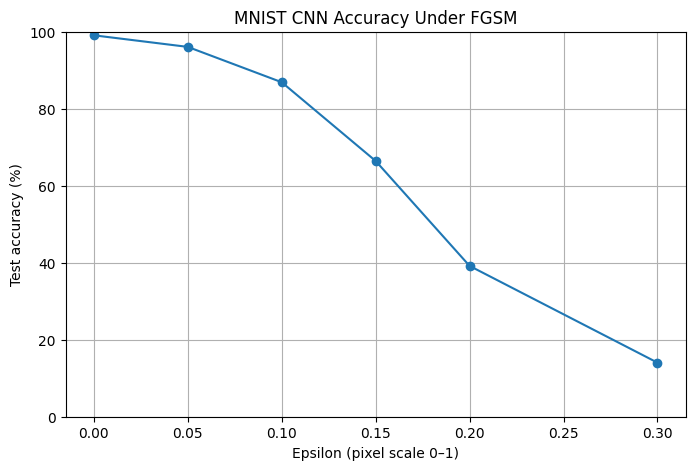

In [ ]:
def evaluate_fgsm_accuracy(model, loader, epsilon):
    model.eval() /// Model will be evaluating instead of training
    correct, total = 0, 0 /// Initialize counters
    for x, y in loader:  /// Loop through test data
        x, y = x.to(DEVICE), y.to(DEVICE)
        x_adv = x if epsilon == 0 else fgsm_attack(model, x, y, epsilon) /// Generate adversarial images
        with torch.no_grad():  /// Evaluate adversarial images
            correct += (model(x_adv).argmax(1) == y).sum().item()
        total += y.size(0)
    return 100.0 * correct / total /// Calculate Accuracy

epsilon_values = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30] /// Define Epsilon values
fgsm_rows = []
for eps in epsilon_values:  /// Run the FGSM experiemnts 
    acc = evaluate_fgsm_accuracy(model, test_loader, eps)
    fgsm_rows.append({"Epsilon": eps, "Accuracy (%)": acc}) /// Store results
    print(f"Epsilon {eps:.2f}: accuracy {acc:.2f}%")  /// Display results
fgsm_df = pd.DataFrame(fgsm_rows)
display(fgsm_df)

plt.figure(figsize=(8, 5))
plt.plot(fgsm_df["Epsilon"], fgsm_df["Accuracy (%)"], marker="o")
plt.xlabel("Epsilon (pixel scale 0–1)")
plt.ylabel("Test accuracy (%)")
plt.title("MNIST CNN Accuracy Under FGSM")
plt.ylim(0, 100)
plt.grid(True)
plt.show()

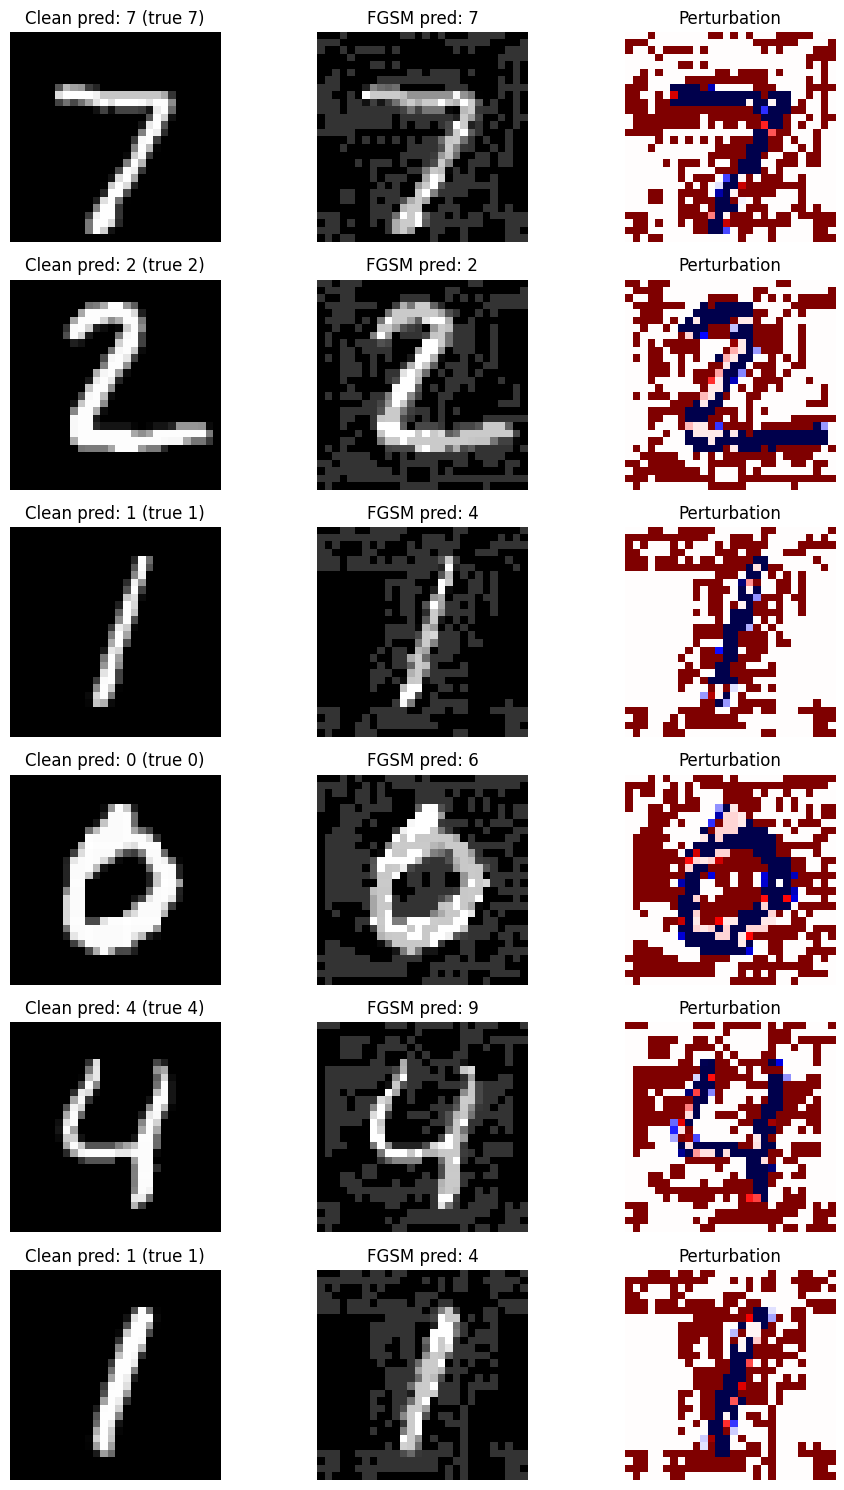

In [8]:
images, labels = next(iter(test_loader))
images, labels = images.to(DEVICE), labels.to(DEVICE)
DISPLAY_EPSILON = 0.20
adv_images = fgsm_attack(model, images, labels, DISPLAY_EPSILON)
with torch.no_grad():
    clean_preds = model(images).argmax(1)
    adv_preds = model(adv_images).argmax(1)

def denormalize(x):
    return (x * STD + MEAN).clamp(0, 1)

fig, axes = plt.subplots(6, 3, figsize=(10, 15))
for i in range(6):
    original = denormalize(images[i]).cpu().squeeze().numpy()
    adversarial = denormalize(adv_images[i]).cpu().squeeze().numpy()
    delta = adversarial - original
    axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Clean pred: {clean_preds[i].item()} (true {labels[i].item()})")
    axes[i, 1].imshow(adversarial, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"FGSM pred: {adv_preds[i].item()}")
    axes[i, 2].imshow(delta, cmap="seismic", vmin=-DISPLAY_EPSILON, vmax=DISPLAY_EPSILON)
    axes[i, 2].set_title("Perturbation")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
def attack_success_rate(model, loader, epsilon):
    model.eval()
    originally_correct, fooled = 0, 0
    for x, y in loader: ## Loop through the dataset 
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.no_grad(): ## Get the original predictions
            clean_pred = model(x).argmax(1)
        x_adv = fgsm_attack(model, x, y, epsilon) ## Generate adversarial images
        with torch.no_grad(): ## Get pedictions for adversarial images
            adv_pred = model(x_adv).argmax(1)
        mask = clean_pred.eq(y) ## Identify orginal correct predictions
        originally_correct += mask.sum().item()
        fooled += (mask & adv_pred.ne(y)).sum().item() ## Count successful attacks
    return float("nan") if originally_correct == 0 else 100.0 * fooled / originally_correct ## Calculate the attack success rate

asr_rows = [] ## Calculate attack success rate for different epsilons 
for eps in epsilon_values[1:]:
    asr = attack_success_rate(model, test_loader, eps)
    asr_rows.append({"Epsilon": eps, "Attack success rate (%)": asr})
    print(f"Epsilon {eps:.2f}: ASR {asr:.2f}%")
asr_df = pd.DataFrame(asr_rows)
display(asr_df)

Epsilon 0.05: ASR 3.04%
Epsilon 0.10: ASR 12.30%
Epsilon 0.15: ASR 32.95%
Epsilon 0.20: ASR 60.46%
Epsilon 0.30: ASR 85.83%


,Epsilon,Attack success rate (%)
0,0.05,3.038256
1,0.10,12.304431
2,0.15,32.946402
3,0.20,60.462299
4,0.30,85.828202


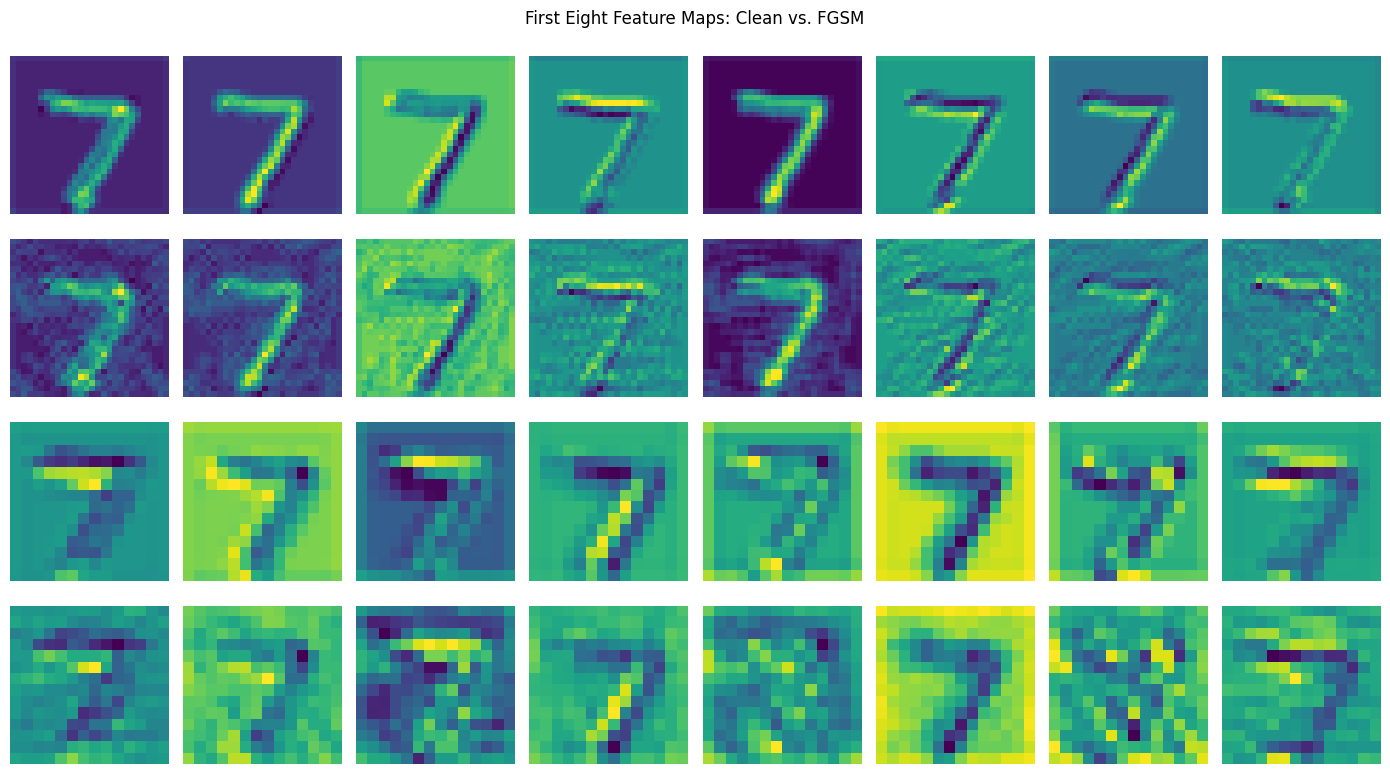

In [ ]:
def get_feature_maps(model, image):
    captured = {} ## Create dictionary to store feature maps
    def hook_for(name): ## Define hook function to capture output of specific layer
        def hook(module, inputs, output):
            captured[name] = output.detach().cpu()
        return hook
    h1 = model.conv1.register_forward_hook(hook_for("conv1")) ## Register hooks for layer 1
    h2 = model.conv2.register_forward_hook(hook_for("conv2")) ## Register hooks for layer 2
    model.eval() ## Model set to evaluation mode
    with torch.no_grad(): ## Process the image
        model(image)
    h1.remove() ## Remove hooks
    h2.remove()
    return captured ## Return feature maps

## Select an image to examine 
sample, sample_label = images[:1], labels[:1]
sample_adv = fgsm_attack(model, sample, sample_label, DISPLAY_EPSILON)
clean_maps = get_feature_maps(model, sample)
adv_maps = get_feature_maps(model, sample_adv)

## Organize feature maps for visualization
rows = [
    (clean_maps["conv1"], "Clean Conv1"),
    (adv_maps["conv1"], "Adversarial Conv1"),
    (clean_maps["conv2"], "Clean Conv2"),
    (adv_maps["conv2"], "Adversarial Conv2")
]
fig, axes = plt.subplots(4, 8, figsize=(14, 8)) ## Create the visulaization layout
for r, (maps, label) in enumerate(rows): ## Loop through rows and feature maps
    for c in range(8):
        axes[r, c].imshow(maps[0, c].numpy(), cmap="viridis")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_ylabel(label)
plt.suptitle("First Eight Feature Maps: Clean vs. FGSM")
plt.tight_layout()
plt.show()

,Evaluation,Accuracy (%)
0,Clean,99.07
1,FGSM (epsilon=0.20),39.17
2,"PGD (10 steps, epsilon=0.20)",53.91


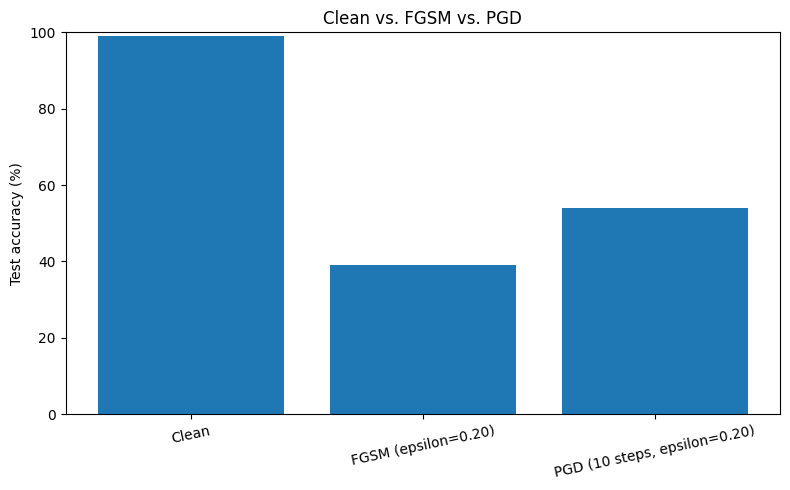

In [ ]:
def pgd_attack(model, images, labels, epsilon=0.20,
               alpha=0.03, iterations=20, random_start=True):
    model.eval() ## Set model to evaluation mode
    original = images.detach().clone().to(DEVICE) ## Create copy of orginal images
    labels = labels.to(DEVICE)
    eps_norm, alpha_norm = epsilon / STD, alpha / STD ## Adjust epsilon and alpha normalization

    if random_start: ## Determine start point of PGD attack
        adv = original + torch.empty_like(original).uniform_(-eps_norm, eps_norm)
    else:
        adv = original.clone()

    min_value, max_value = (0.0 - MEAN) / STD, (1.0 - MEAN) / STD

    for _ in range(iterations): ## PGD attack iteration loop
        adv = adv.detach().requires_grad_(True) ## Enable gradient tracking
        loss = F.cross_entropy(model(adv), labels) ## Calculate the classification loss
        model.zero_grad(set_to_none=True) ## Clear previous gradients 
        loss.backward() ## Calculate the gradients 

        with torch.no_grad(): ## Update adversarial image
            adv = adv + alpha_norm * adv.grad.sign()
            delta = torch.clamp(adv - original, -eps_norm, eps_norm) ## Calculate and restrict the perturbation
            adv = original + delta ## Reconstruct the adversarial image
            adv = torch.clamp(adv, min_value, max_value) 

    return adv.detach() ## Return final adversarial image

## Evaluate PGD accuracy 
def evaluate_pgd_accuracy(model, loader, epsilon=0.20, alpha=0.01, iterations=10):
    model.eval() ## Set evaluation mode
    correct, total = 0, 0 ## Initialize counters
    for x, y in loader: ## Process test dataset 
        x, y = x.to(DEVICE), y.to(DEVICE)
        x_adv = pgd_attack(model, x, y, epsilon, alpha, iterations) ## Generate adversarial images
        with torch.no_grad(): ## Evaluate the adversarial images
            correct += (model(x_adv).argmax(1) == y).sum().item()
        total += y.size(0) ## Count total number of images
    return 100.0 * correct / total ## Calculate the final accuracy 

PGD_EPSILON, PGD_ALPHA, PGD_STEPS = 0.20, 0.01, 10 ## Set PGD experiment parameters
pgd_accuracy = evaluate_pgd_accuracy( ## Evaluate PGD accuracy
    model, test_loader, PGD_EPSILON, PGD_ALPHA, PGD_STEPS
)
fgsm_020 = evaluate_fgsm_accuracy(model, test_loader, PGD_EPSILON) ## Evlaute FGSM accuracy 
comparison_df = pd.DataFrame([ ## Create comparison table
    {"Evaluation": "Clean", "Accuracy (%)": clean_accuracy},
    {"Evaluation": "FGSM (epsilon=0.20)", "Accuracy (%)": fgsm_020},
    {"Evaluation": f"PGD ({PGD_STEPS} steps, epsilon=0.20)", "Accuracy (%)": pgd_accuracy}
])
display(comparison_df) ## Display table

plt.figure(figsize=(8, 5))
plt.bar(comparison_df["Evaluation"], comparison_df["Accuracy (%)"])
plt.ylabel("Test accuracy (%)")
plt.title("Clean vs. FGSM vs. PGD")
plt.ylim(0, 100)
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()